### Imports

In [17]:
import os
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import joblib

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


### Import scikit-learn libraries

In [18]:
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.linear_model import (
    LogisticRegression,
    LinearRegression
)

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Scikit-learn libraries imported successfully.")

Scikit-learn libraries imported successfully.


### Import SMOTE

In [19]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("SMOTE imported successfully.")

SMOTE imported successfully.


### Load the cleaned CSV

In [20]:
df = pd.read_csv("titanic.csv")

print("Titanic dataset loaded from titanic.csv")
print("Shape:", df.shape)

display(df.head())

Titanic dataset loaded from titanic.csv
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [22]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())

classification_features = [
    "age",
    "fare",
    "sex",
    "embarked",
    "pclass",
    "sibsp",
    "parch"
]

target = "survived"

X = df[classification_features].copy()
y = df[target].copy()

print("Feature columns:")
print(classification_features)

print("\nTarget:")
print(target)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Missing values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
Feature columns:
['age', 'fare', 'sex', 'embarked', 'pclass', 'sibsp', 'parch']

Target:
survived

X shape: (891, 7)
y shape: (891,)


In [23]:
class_counts = y.value_counts().sort_index()

class_percentages = (
    y.value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages)

class_balance_df = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

class_balance_df.index = [
    "Not Survived",
    "Survived"
]

print(class_balance_df)

Class counts:
survived
0    549
1    342
Name: count, dtype: int64

Class percentages:
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64
              Count  Percentage
Not Survived    549       61.62
Survived        342       38.38


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (712, 7)
Testing set: (179, 7)


In [25]:
print("Overall class distribution:")
print(y.value_counts(normalize=True).sort_index())

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Overall class distribution:
survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

Training class distribution:
survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

Testing class distribution:
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [26]:
numeric_features = [
    "age",
    "fare",
    "pclass",
    "sibsp",
    "parch"
]

categorical_features = [
    "sex",
    "embarked"
]

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['age', 'fare', 'pclass', 'sibsp', 'parch']

Categorical features:
['sex', 'embarked']


In [28]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

print("Numeric preprocessing pipeline created.")

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

print("Categorical preprocessing pipeline created.")

Numeric preprocessing pipeline created.
Categorical preprocessing pipeline created.


In [29]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("ColumnTransformer created successfully.")

ColumnTransformer created successfully.


In [30]:
models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        )
}

print("Models defined:")
for name in models:
    print("-", name)

Models defined:
- Logistic Regression
- Decision Tree
- Random Forest


In [31]:
trained_models = {}

for name, model in models.items():

    model_pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    model_pipeline.fit(
        X_train,
        y_train
    )

    trained_models[name] = model_pipeline

    print(
        f"{name}: training complete"
    )

Logistic Regression: training complete
Decision Tree: training complete
Random Forest: training complete


In [32]:
predictions = {}
probabilities = {}

for name, model_pipeline in trained_models.items():

    predictions[name] = (
        model_pipeline.predict(X_test)
    )

    probabilities[name] = (
        model_pipeline.predict_proba(X_test)[:, 1]
    )

print("Predictions generated for all models.")

Predictions generated for all models.


In [33]:
classification_results = []

for name in trained_models:

    y_pred = predictions[name]
    y_prob = probabilities[name]

    classification_results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "Precision": precision_score(
            y_test,
            y_pred
        ),

        "Recall": recall_score(
            y_test,
            y_pred
        ),

        "F1": f1_score(
            y_test,
            y_pred
        ),

        "AUC": roc_auc_score(
            y_test,
            y_prob
        )
    })

classification_results = pd.DataFrame(
    classification_results
)

classification_results = (
    classification_results
    .round(4)
)

display(classification_results)

classification_results.to_csv(
    "outputs/classification_results.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8437
1,Decision Tree,0.7765,0.7544,0.6232,0.6825,0.7927
2,Random Forest,0.8101,0.7869,0.6957,0.7385,0.8317


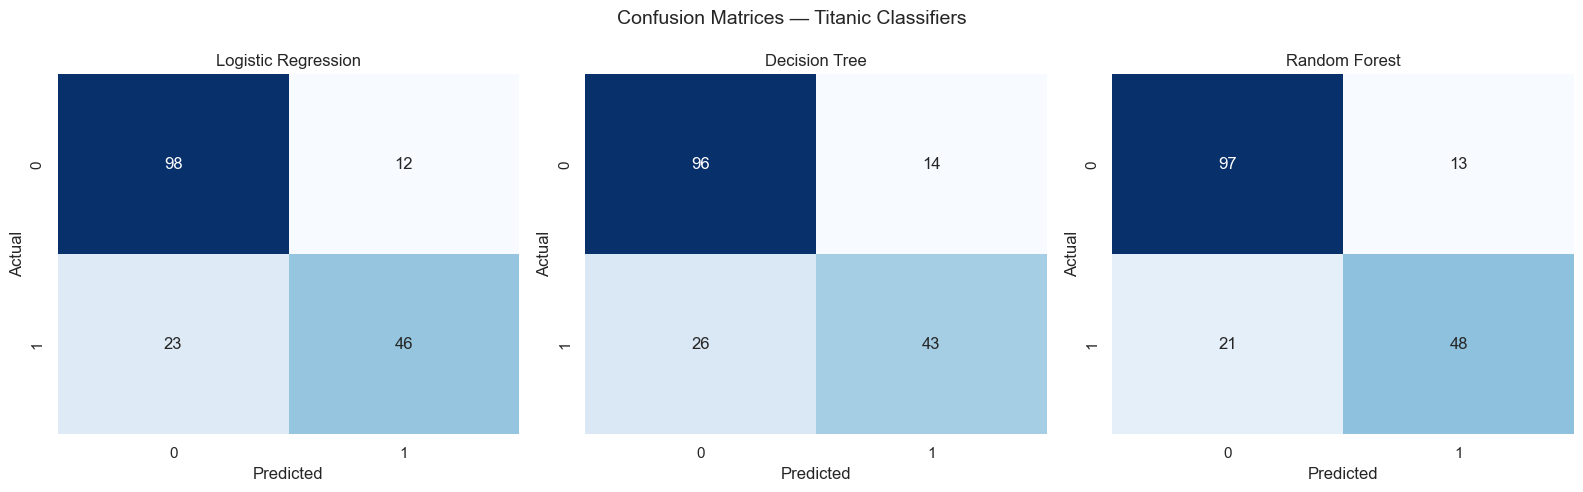

In [34]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

for ax, name in zip(
    axes,
    trained_models.keys()
):

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(name)

    ax.set_xlabel(
        "Predicted"
    )

    ax.set_ylabel(
        "Actual"
    )

plt.suptitle(
    "Confusion Matrices — Titanic Classifiers",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

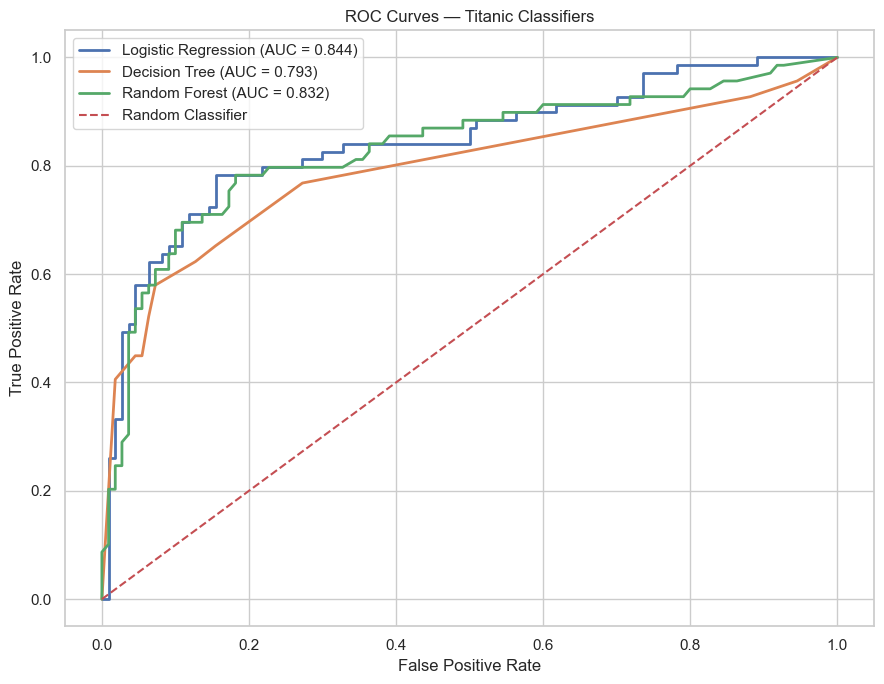

In [35]:
plt.figure(figsize=(9, 7))

for name in trained_models:

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[name]
    )

    auc_value = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curves — Titanic Classifiers"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "outputs/figures/roc_curves.png",
    dpi=300
)

plt.show()

Number of transformed features:
10

Feature names:
['numeric__age' 'numeric__fare' 'numeric__pclass' 'numeric__sibsp'
 'numeric__parch' 'categorical__sex_female' 'categorical__sex_male'
 'categorical__embarked_C' 'categorical__embarked_Q'
 'categorical__embarked_S']


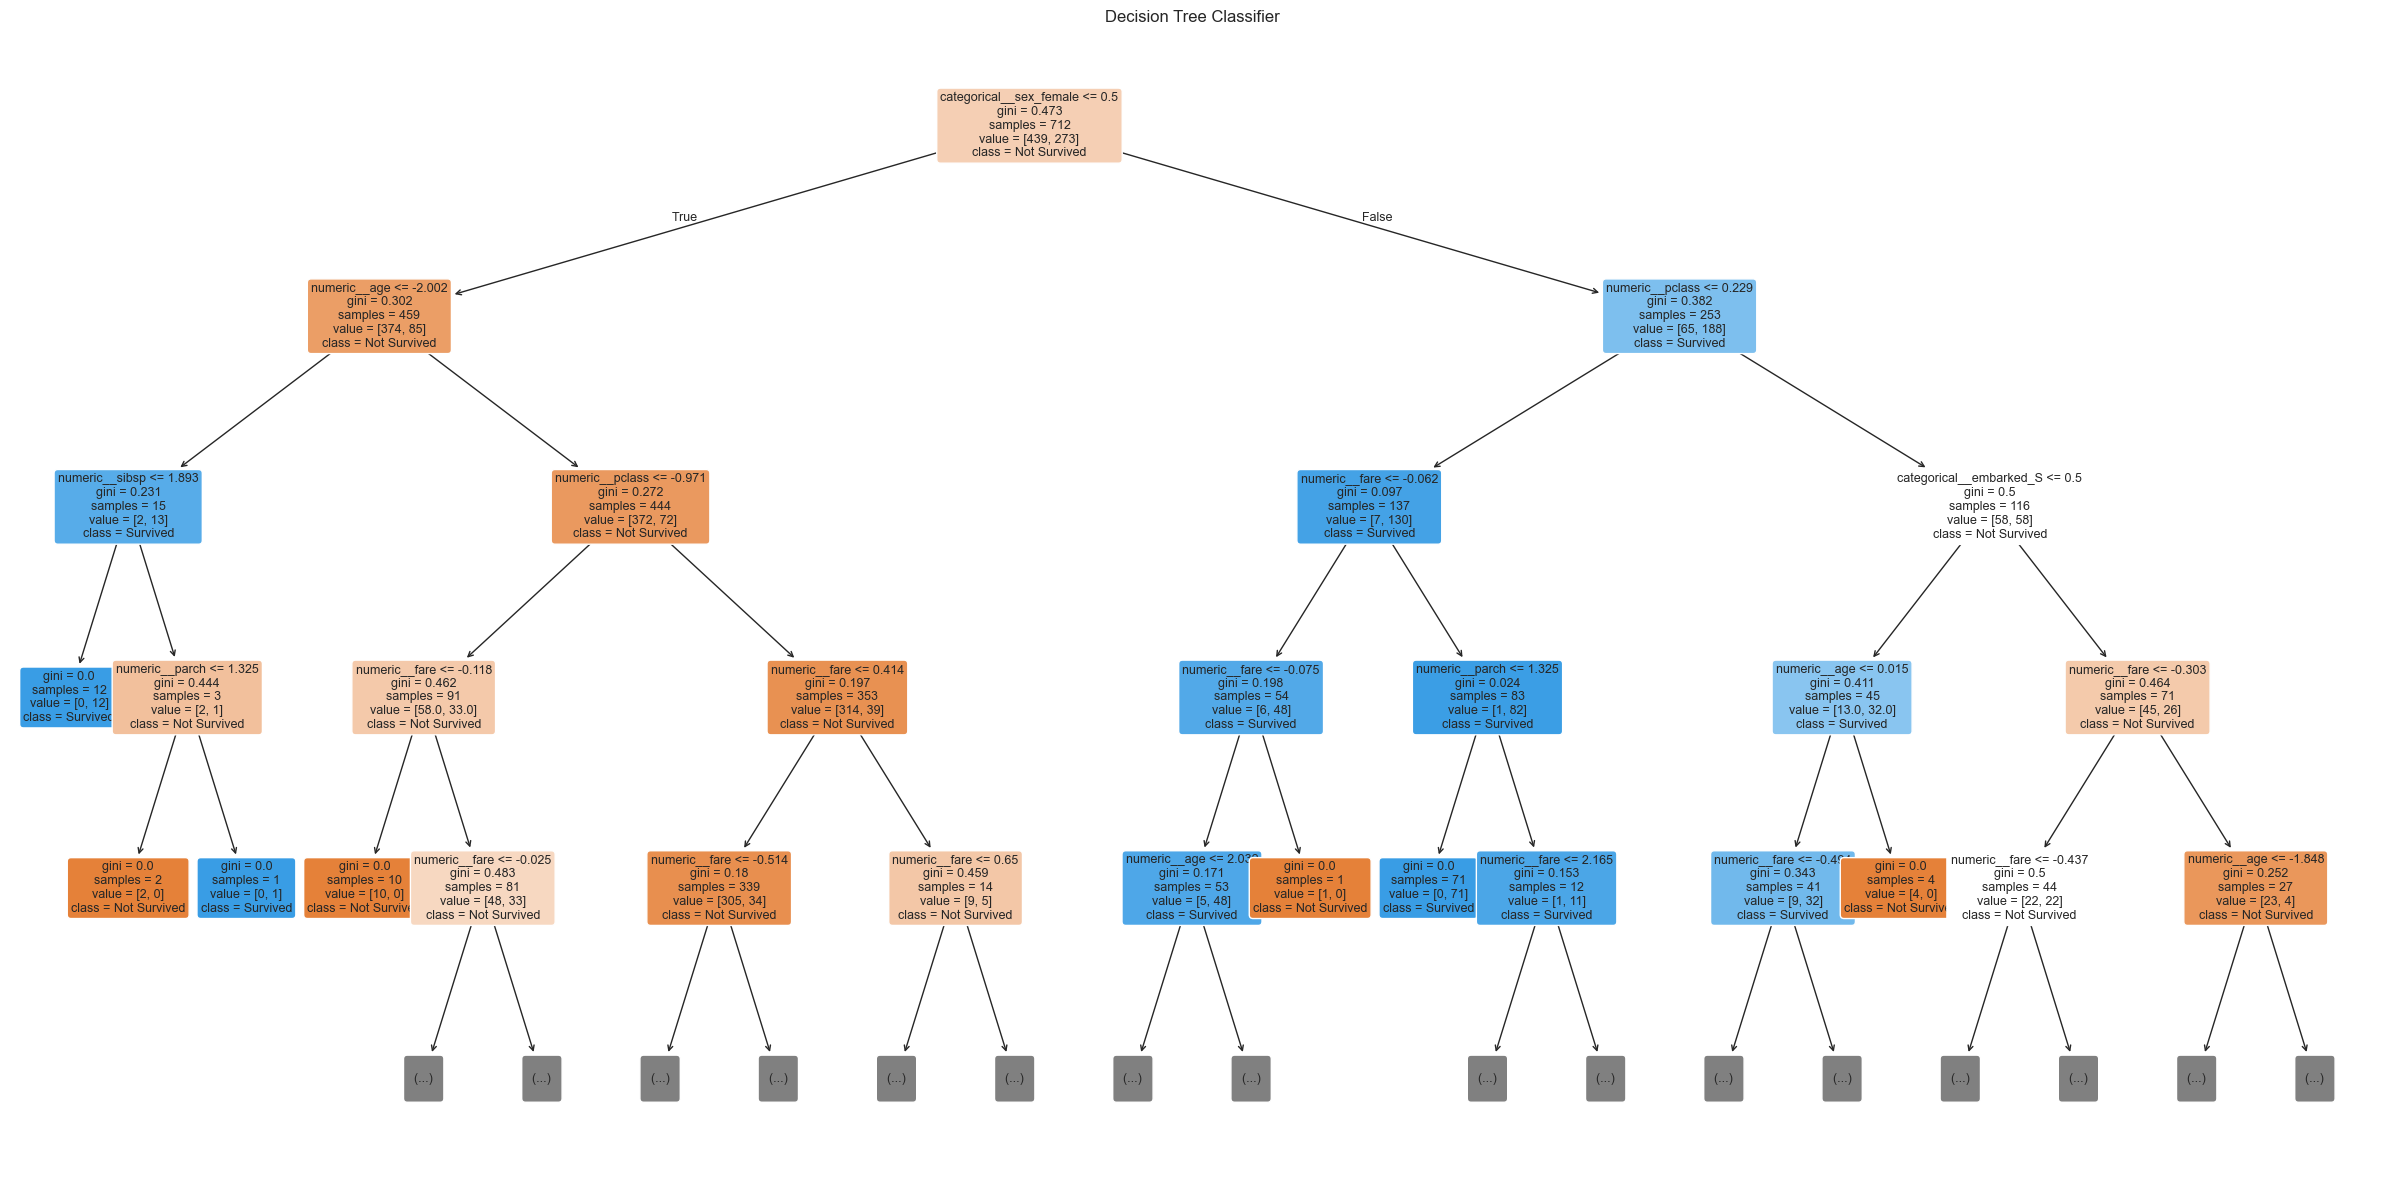

In [37]:
tree_pipeline = trained_models[
    "Decision Tree"
]

fitted_preprocessor = (
    tree_pipeline
    .named_steps["preprocessor"]
)

tree_model = (
    tree_pipeline
    .named_steps["model"]
)

feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

print("Number of transformed features:")
print(len(feature_names))

print("\nFeature names:")
print(feature_names)


plt.figure(
    figsize=(24, 12)
)

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=[
        "Not Survived",
        "Survived"
    ],
    filled=True,
    rounded=True,
    max_depth=4,
    fontsize=9
)

plt.title(
    "Decision Tree Classifier"
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/decision_tree.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
baseline_pred = predictions[
    "Logistic Regression"
]

print(
    "Baseline predictions ready."
)

Baseline predictions ready.


In [39]:
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

balanced_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            balanced_model
        )
    ]
)

balanced_pipeline.fit(
    X_train,
    y_train
)

balanced_pred = (
    balanced_pipeline.predict(
        X_test
    )
)

print(
    "Class-weight balanced model trained."
)

Class-weight balanced model trained.


In [40]:
smote_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_pipeline = ImbPipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "smote",
            SMOTE(
                random_state=42
            )
        ),
        (
            "model",
            smote_model
        )
    ]
)

smote_pipeline.fit(
    X_train,
    y_train
)

smote_pred = (
    smote_pipeline.predict(
        X_test
    )
)

print(
    "SMOTE model trained."
)

SMOTE model trained.


In [41]:
imbalance_results = []

variants = {

    "Baseline":
        baseline_pred,

    "Class Weight Balanced":
        balanced_pred,

    "SMOTE":
        smote_pred
}

for name, pred in variants.items():

    imbalance_results.append({

        "Strategy": name,

        "Precision": precision_score(
            y_test,
            pred
        ),

        "Recall": recall_score(
            y_test,
            pred
        ),

        "F1": f1_score(
            y_test,
            pred
        )
    })

imbalance_df = pd.DataFrame(
    imbalance_results
)

imbalance_df = imbalance_df.round(4)

display(imbalance_df)

imbalance_df.to_csv(
    "outputs/imbalance_results.csv",
    index=False
)

,Strategy,Precision,Recall,F1
0,Baseline,0.7931,0.6667,0.7244
1,Class Weight Balanced,0.7297,0.7826,0.7552
2,SMOTE,0.7397,0.7826,0.7606


In [42]:
best_imbalance_strategy = (
    imbalance_df
    .loc[
        imbalance_df["F1"].idxmax(),
        "Strategy"
    ]
)

best_imbalance_f1 = (
    imbalance_df["F1"].max()
)

print(
    "Best imbalance strategy:",
    best_imbalance_strategy
)

print(
    f"Best F1 score: {best_imbalance_f1:.4f}"
)

Best imbalance strategy: SMOTE
Best F1 score: 0.7606


Among the three imbalance-handling approaches, [strategy] produced the highest F1 score of [value]. This indicates that it provided the strongest balance between precision and recall on the held-out test set. The baseline, class-weighted, and SMOTE variants were evaluated on the same untouched test set, while SMOTE was restricted to the training pipeline to avoid data leakage.

In [43]:
rf_for_tuning = RandomForestClassifier(
    random_state=42,
    oob_score=True,
    n_jobs=-1
)

rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            rf_for_tuning
        )
    ]
)

In [44]:
param_grid = {

    "model__n_estimators": [
        100,
        200,
        300
    ],

    "model__max_depth": [
        None,
        5,
        10,
        15
    ],

    "model__max_features": [
        "sqrt",
        "log2"
    ]
}

print(param_grid)

{'model__n_estimators': [100, 200, 300], 'model__max_depth': [None, 5, 10, 15], 'model__max_features': ['sqrt', 'log2']}


In [45]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train,
    y_train
)

print("Grid search completed.")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Grid search completed.


In [46]:
print("Best parameters:")
print(grid_search.best_params_)

print(
    "\nBest cross-validation F1:"
)

print(
    round(
        grid_search.best_score_,
        4
    )
)

Best parameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__n_estimators': 100}

Best cross-validation F1:
0.7441


In [47]:
best_rf_pipeline = (
    grid_search.best_estimator_
)

best_rf_model = (
    best_rf_pipeline
    .named_steps["model"]
)

oob_score = best_rf_model.oob_score_

print(
    "Random Forest OOB Score:",
    round(oob_score, 4)
)

Random Forest OOB Score: 0.816


In [48]:
tuned_rf_pred = (
    best_rf_pipeline.predict(
        X_test
    )
)

tuned_rf_prob = (
    best_rf_pipeline
    .predict_proba(X_test)[:, 1]
)

tuned_rf_metrics = {

    "Accuracy":
        accuracy_score(
            y_test,
            tuned_rf_pred
        ),

    "Precision":
        precision_score(
            y_test,
            tuned_rf_pred
        ),

    "Recall":
        recall_score(
            y_test,
            tuned_rf_pred
        ),

    "F1":
        f1_score(
            y_test,
            tuned_rf_pred
        ),

    "AUC":
        roc_auc_score(
            y_test,
            tuned_rf_prob
        )
}

print(
    pd.Series(
        tuned_rf_metrics
    ).round(4)
)

Accuracy     0.8156
Precision    0.8103
Recall       0.6812
F1           0.7402
AUC          0.8413
dtype: float64


In [49]:
regression_features = [
    "age",
    "pclass",
    "sibsp",
    "parch",
    "sex",
    "embarked"
]

X_reg = df[
    regression_features
].copy()

y_reg = df[
    "fare"
].copy()

print(
    "Regression X shape:",
    X_reg.shape
)

print(
    "Regression y shape:",
    y_reg.shape
)

Regression X shape: (891, 6)
Regression y shape: (891,)


In [50]:
X_reg_train, X_reg_test, y_reg_train, y_reg_test = (
    train_test_split(
        X_reg,
        y_reg,
        test_size=0.20,
        random_state=42
    )
)

print(
    "Regression training:",
    X_reg_train.shape
)

print(
    "Regression testing:",
    X_reg_test.shape
)

Regression training: (712, 6)
Regression testing: (179, 6)


In [51]:
reg_numeric_features = [
    "age",
    "pclass",
    "sibsp",
    "parch"
]

reg_categorical_features = [
    "sex",
    "embarked"
]

reg_numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

reg_categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

reg_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            reg_numeric_pipeline,
            reg_numeric_features
        ),
        (
            "categorical",
            reg_categorical_pipeline,
            reg_categorical_features
        )
    ]
)

print(
    "Regression preprocessor created."
)

Regression preprocessor created.


In [52]:
regression_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            reg_preprocessor
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)

regression_pipeline.fit(
    X_reg_train,
    y_reg_train
)

print(
    "Linear regression trained."
)

Linear regression trained.


In [53]:
reg_predictions = (
    regression_pipeline.predict(
        X_reg_test
    )
)

print(
    "Regression predictions generated."
)

Regression predictions generated.


In [54]:
mae = mean_absolute_error(
    y_reg_test,
    reg_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        reg_predictions
    )
)

r2 = r2_score(
    y_reg_test,
    reg_predictions
)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²:", round(r2, 4))

MAE: 20.8094
RMSE: 30.4731
R²: 0.3999


In [55]:
n = len(y_reg_test)

p = (
    regression_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
    .shape[0]
)

adjusted_r2 = (
    1
    -
    (
        (1 - r2)
        * (n - 1)
        /
        (n - p - 1)
    )
)

print(
    "Adjusted R²:",
    round(adjusted_r2, 4)
)

Adjusted R²: 0.3679


In [56]:
regression_results = pd.DataFrame({

    "Model": [
        "Multivariate Linear Regression"
    ],

    "MAE": [mae],

    "RMSE": [rmse],

    "R2": [r2],

    "Adjusted_R2": [
        adjusted_r2
    ]
})

regression_results = (
    regression_results.round(4)
)

display(regression_results)

regression_results.to_csv(
    "outputs/regression_results.csv",
    index=False
)

,Model,MAE,RMSE,R2,Adjusted_R2
0,Multivariate Linear Regression,20.8094,30.4731,0.3999,0.3679


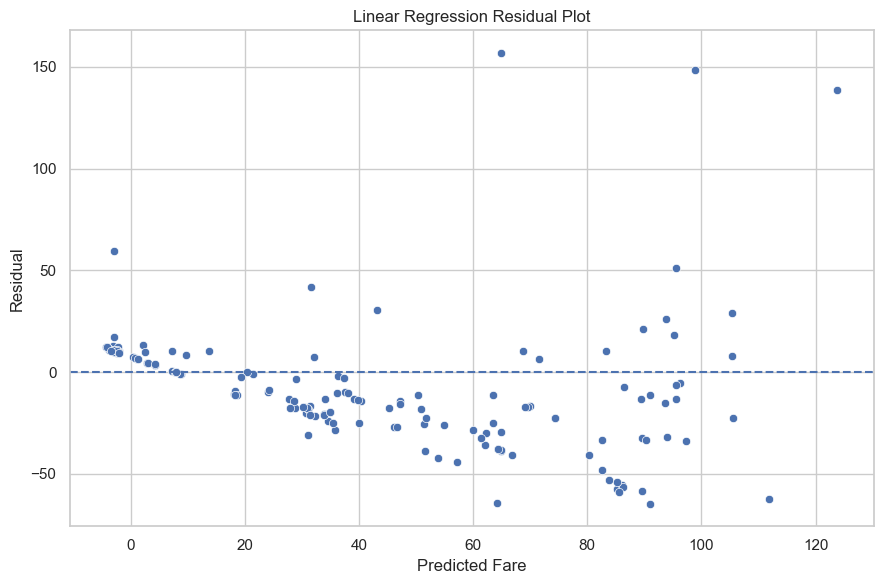

In [57]:
residuals = (
    y_reg_test -
    reg_predictions
)

plt.figure(
    figsize=(9, 6)
)

sns.scatterplot(
    x=reg_predictions,
    y=residuals
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Predicted Fare"
)

plt.ylabel(
    "Residual"
)

plt.title(
    "Linear Regression Residual Plot"
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/regression_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
print(
    "Residual mean:",
    round(
        residuals.mean(),
        4
    )
)

print(
    "Residual standard deviation:",
    round(
        residuals.std(),
        4
    )
)

Residual mean: -6.3043
Residual standard deviation: 29.8975


The residual plot shows evidence of heteroscedasticity because the spread of residuals increases as predicted fare increases. This suggests that the variance of prediction errors is not constant across the range of predicted fares.

In [59]:
tuned_rf_row = pd.DataFrame([{

    "Model": "Tuned Random Forest",

    "Accuracy":
        tuned_rf_metrics["Accuracy"],

    "Precision":
        tuned_rf_metrics["Precision"],

    "Recall":
        tuned_rf_metrics["Recall"],

    "F1":
        tuned_rf_metrics["F1"],

    "AUC":
        tuned_rf_metrics["AUC"]
}])

final_classification_results = pd.concat(
    [
        classification_results,
        tuned_rf_row
    ],
    ignore_index=True
)

final_classification_results = (
    final_classification_results
    .round(4)
)

display(
    final_classification_results
)

final_classification_results.to_csv(
    "outputs/final_classification_results.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8437
1,Decision Tree,0.7765,0.7544,0.6232,0.6825,0.7927
2,Random Forest,0.8101,0.7869,0.6957,0.7385,0.8317
3,Tuned Random Forest,0.8156,0.8103,0.6812,0.7402,0.8413


In [60]:
best_classifier_row = (
    final_classification_results
    .sort_values(
        "F1",
        ascending=False
    )
    .iloc[0]
)

print(
    "Best classifier by F1:"
)

print(
    best_classifier_row
)

Best classifier by F1:
Model        Tuned Random Forest
Accuracy                  0.8156
Precision                 0.8103
Recall                    0.6812
F1                        0.7402
AUC                       0.8413
Name: 3, dtype: object


In [61]:
print("=" * 80)
print("CLASSIFICATION MODEL COMPARISON")
print("=" * 80)

display(
    final_classification_results
)

print("\n")

print("=" * 80)
print("REGRESSION MODEL RESULTS")
print("=" * 80)

display(
    regression_results
)

CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8437
1,Decision Tree,0.7765,0.7544,0.6232,0.6825,0.7927
2,Random Forest,0.8101,0.7869,0.6957,0.7385,0.8317
3,Tuned Random Forest,0.8156,0.8103,0.6812,0.7402,0.8413




REGRESSION MODEL RESULTS


,Model,MAE,RMSE,R2,Adjusted_R2
0,Multivariate Linear Regression,20.8094,30.4731,0.3999,0.3679


In [62]:
with open(
    "outputs/final_model_report.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "CLASSIFICATION MODEL COMPARISON\n"
    )

    f.write(
        "=" * 70 + "\n"
    )

    f.write(
        final_classification_results
        .to_string(index=False)
    )

    f.write(
        "\n\nREGRESSION MODEL RESULTS\n"
    )

    f.write(
        "=" * 70 + "\n"
    )

    f.write(
        regression_results
        .to_string(index=False)
    )

    f.write(
        "\n\nBEST RANDOM FOREST PARAMETERS\n"
    )

    f.write(
        str(
            grid_search.best_params_
        )
    )

    f.write(
        "\n\nBEST RANDOM FOREST CV F1\n"
    )

    f.write(
        str(grid_search.best_score_)
    )

    f.write(
        "\n\nRANDOM FOREST OOB SCORE\n"
    )

    f.write(
        str(oob_score)
    )

In [63]:
full_pipeline = best_rf_pipeline

print(
    "Final pipeline selected:"
)

print(full_pipeline)

Final pipeline selected:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fare', 'pclass',
                                                   'sibsp', 'parch']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                           

In [64]:
pipeline_path = (
    "models/titanic_pipeline.joblib"
)

joblib.dump(
    full_pipeline,
    pipeline_path
)

print(
    f"Complete pipeline saved to: "
    f"{pipeline_path}"
)

Complete pipeline saved to: models/titanic_pipeline.joblib


In [65]:
loaded_pipeline = joblib.load(
    "models/titanic_pipeline.joblib"
)

print(
    "Pipeline successfully reloaded."
)

Pipeline successfully reloaded.


In [66]:
raw_sample = X_test.iloc[[0]]

actual_value = y_test.iloc[0]

prediction = (
    loaded_pipeline.predict(
        raw_sample
    )
)

probability = (
    loaded_pipeline
    .predict_proba(raw_sample)[0, 1]
)

print("Raw input:")
display(raw_sample)

print(
    "Predicted survival:",
    prediction[0]
)

print(
    "Survival probability:",
    round(
        probability,
        4
    )
)

print(
    "Actual value:",
    actual_value
)

Raw input:


,age,fare,sex,embarked,pclass,sibsp,parch
565,24.0,24.15,male,S,3,2,0


Predicted survival: 0
Survival probability: 0.1168
Actual value: 0


In [67]:
print("=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

assert len(trained_models) == 3

assert set(
    trained_models.keys()
) == {
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
}

assert (
    len(classification_results) == 3
)

assert (
    len(imbalance_df) == 3
)

assert (
    "SMOTE" in imbalance_df["Strategy"].values
)

assert (
    "Class Weight Balanced"
    in imbalance_df["Strategy"].values
)

assert (
    grid_search.best_params_
    is not None
)

assert (
    best_rf_model.oob_score_
    is not None
)

assert os.path.exists(
    "models/titanic_pipeline.joblib"
)

assert len(
    prediction
) == 1

print("✓ Three classifiers trained")
print("✓ Full classification metrics calculated")
print("✓ Imbalance comparison completed")
print("✓ SMOTE comparison completed")
print("✓ GridSearchCV completed")
print("✓ OOB score calculated")
print("✓ Regression completed")
print("✓ Complete pipeline saved")
print("✓ Pipeline successfully reloaded")
print("✓ Raw-input prediction successful")

print("\nALL MODELING VALIDATION CHECKS PASSED.")

FINAL VALIDATION
✓ Three classifiers trained
✓ Full classification metrics calculated
✓ Imbalance comparison completed
✓ SMOTE comparison completed
✓ GridSearchCV completed
✓ OOB score calculated
✓ Regression completed
✓ Complete pipeline saved
✓ Pipeline successfully reloaded
✓ Raw-input prediction successful

ALL MODELING VALIDATION CHECKS PASSED.


In [68]:
best = (
    final_classification_results
    .sort_values(
        "F1",
        ascending=False
    )
    .iloc[0]
)

print(
    f"Best classifier: {best['Model']}"
)

print(
    f"Accuracy: {best['Accuracy']:.4f}"
)

print(
    f"Precision: {best['Precision']:.4f}"
)

print(
    f"Recall: {best['Recall']:.4f}"
)

print(
    f"F1: {best['F1']:.4f}"
)

print(
    f"AUC: {best['AUC']:.4f}"
)

print(
    f"\nRegression MAE: {mae:.4f}"
)

print(
    f"Regression RMSE: {rmse:.4f}"
)

print(
    f"Regression R²: {r2:.4f}"
)

print(
    f"Regression Adjusted R²: {adjusted_r2:.4f}"
)

print(
    f"\nBest imbalance strategy: "
    f"{best_imbalance_strategy}"
)

print(
    f"Random Forest OOB: "
    f"{oob_score:.4f}"
)

Best classifier: Tuned Random Forest
Accuracy: 0.8156
Precision: 0.8103
Recall: 0.6812
F1: 0.7402
AUC: 0.8413

Regression MAE: 20.8094
Regression RMSE: 30.4731
Regression R²: 0.3999
Regression Adjusted R²: 0.3679

Best imbalance strategy: SMOTE
Random Forest OOB: 0.8160
